# 10.1 문제 정의
스피드데이팅 데이터셋을 이용해서 커플 성사 여부를 예측하라.

스피드데이팅에 대한 데이터입니다. 스피드 데이팅은 남녀 수십 쌍이 짧은 시간을 보낸 뒤 서로에 대한 호감도를 표현하여 짝을 매칭하는 이벤트입니다. 독립변수로는 상대방과 내 정보, 개인의 취향, 상대방에 대한 평가 등이 있으며, 매칭 성사 여부가 종속변수 입니다.

## 10.2 라이브러리 및 데이터 불러오기, 데이터 확인하기

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_url = 'https://media.githubusercontent.com/media/musthave-ML10/data_source/main/dating.csv'
data = pd.read_csv(file_url)

In [2]:
data.head()

,has_null,gender,age,age_o,race,race_o,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,...,funny_partner,ambition_partner,shared_interests_partner,interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,like,guess_prob_liked,met,match
0,0,female,21.0,27.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,35.0,20.0,...,7.0,6.0,5.0,0.14,3.0,2.0,7.0,6.0,0.0,0
1,0,female,21.0,22.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,60.0,0.0,...,8.0,5.0,6.0,0.54,3.0,2.0,7.0,5.0,1.0,0
2,1,female,21.0,22.0,Asian/PacificIslander/Asian-American,Asian/PacificIslander/Asian-American,2.0,4.0,19.0,18.0,...,8.0,5.0,7.0,0.16,3.0,2.0,7.0,NaN,1.0,1
3,0,female,21.0,23.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,30.0,5.0,...,7.0,6.0,8.0,0.61,3.0,2.0,7.0,6.0,0.0,1
4,0,female,21.0,24.0,Asian/PacificIslander/Asian-American,Latino/HispanicAmerican,2.0,4.0,30.0,10.0,...,7.0,6.0,6.0,0.21,3.0,2.0,6.0,6.0,0.0,1


In [3]:
pd.options.display.max_columns = 40  # 총 40개 컬럼까지 출력되도록 설정

In [4]:
data.head()

,has_null,gender,age,age_o,race,race_o,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sincere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,like,guess_prob_liked,met,match
0,0,female,21.0,27.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,35.0,20.0,20.0,20.0,0.0,5.0,6.0,8.0,8.0,8.0,8.0,6.0,15.0,20.0,20.0,15.0,15.0,15.0,6.0,9.0,7.0,7.0,6.0,5.0,0.14,3.0,2.0,7.0,6.0,0.0,0
1,0,female,21.0,22.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,60.0,0.0,0.0,40.0,0.0,0.0,7.0,8.0,10.0,7.0,7.0,5.0,15.0,20.0,20.0,15.0,15.0,15.0,7.0,8.0,7.0,8.0,5.0,6.0,0.54,3.0,2.0,7.0,5.0,1.0,0
2,1,female,21.0,22.0,Asian/PacificIslander/Asian-American,Asian/PacificIslander/Asian-American,2.0,4.0,19.0,18.0,19.0,18.0,14.0,12.0,10.0,10.0,10.0,10.0,10.0,10.0,15.0,20.0,20.0,15.0,15.0,15.0,5.0,8.0,9.0,8.0,5.0,7.0,0.16,3.0,2.0,7.0,NaN,1.0,1
3,0,female,21.0,23.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,30.0,5.0,15.0,40.0,5.0,5.0,7.0,8.0,9.0,8.0,9.0,8.0,15.0,20.0,20.0,15.0,15.0,15.0,7.0,6.0,8.0,7.0,6.0,8.0,0.61,3.0,2.0,7.0,6.0,0.0,1
4,0,female,21.0,24.0,Asian/PacificIslander/Asian-American,Latino/HispanicAmerican,2.0,4.0,30.0,10.0,20.0,10.0,10.0,20.0,8.0,7.0,9.0,6.0,9.0,7.0,15.0,20.0,20.0,15.0,15.0,15.0,5.0,6.0,7.0,7.0,6.0,6.0,0.21,3.0,2.0,6.0,6.0,0.0,1


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8378 entries, 0 to 8377
Data columns (total 39 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   has_null                       8378 non-null   int64  
 1   gender                         8378 non-null   object 
 2   age                            8283 non-null   float64
 3   age_o                          8274 non-null   float64
 4   race                           8315 non-null   object 
 5   race_o                         8305 non-null   object 
 6   importance_same_race           8299 non-null   float64
 7   importance_same_religion       8299 non-null   float64
 8   pref_o_attractive              8289 non-null   float64
 9   pref_o_sincere                 8289 non-null   float64
 10  pref_o_intelligence            8289 non-null   float64
 11  pref_o_funny                   8280 non-null   float64
 12  pref_o_ambitious               8271 non-null   f

In [6]:
round(data.describe(), 2)  # describe를 반올림하여 출력

,has_null,age,age_o,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sincere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,like,guess_prob_liked,met,match
count,8378.00,8283.00,8274.00,8299.00,8299.00,8289.00,8289.00,8289.00,8280.00,8271.00,8249.00,8166.00,8091.00,8072.00,8018.00,7656.00,7302.00,8299.00,8299.00,8299.00,8289.00,8279.00,8257.00,8176.00,8101.00,8082.00,8028.00,7666.00,7311.00,8220.00,8277.00,1800.00,8138.00,8069.00,8003.00,8378.00
mean,0.87,26.36,26.36,3.78,3.65,22.50,17.40,20.27,17.46,10.69,11.85,6.19,7.18,7.37,6.40,6.78,5.47,22.51,17.40,20.27,17.46,10.68,11.85,6.19,7.18,7.37,6.40,6.78,5.47,0.20,5.53,5.57,6.13,5.21,0.05,0.16
std,0.33,3.57,3.56,2.85,2.81,12.57,7.04,6.78,6.09,6.13,6.36,1.95,1.74,1.55,1.95,1.79,2.16,12.59,7.05,6.78,6.09,6.12,6.36,1.95,1.74,1.55,1.95,1.79,2.16,0.30,1.73,4.76,1.84,2.13,0.28,0.37
min,0.00,18.00,18.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,-0.83,1.00,0.00,0.00,0.00,0.00,0.00
25%,1.00,24.00,24.00,1.00,1.00,15.00,15.00,17.39,15.00,5.00,9.52,5.00,6.00,6.00,5.00,6.00,4.00,15.00,15.00,17.39,15.00,5.00,9.52,5.00,6.00,6.00,5.00,6.00,4.00,-0.02,5.00,2.00,5.00,4.00,0.00,0.00
50%,1.00,26.00,26.00,3.00,3.00,20.00,18.37,20.00,18.00,10.00,10.64,6.00,7.00,7.00,7.00,7.00,6.00,20.00,18.18,20.00,18.00,10.00,10.64,6.00,7.00,7.00,7.00,7.00,6.00,0.21,6.00,4.00,6.00,5.00,0.00,0.00
75%,1.00,28.00,28.00,6.00,6.00,25.00,20.00,23.81,20.00,15.00,16.00,8.00,8.00,8.00,8.00,8.00,7.00,25.00,20.00,23.81,20.00,15.00,16.00,8.00,8.00,8.00,8.00,8.00,7.00,0.43,7.00,8.00,7.00,7.00,0.00,0.00
max,1.00,55.00,55.00,10.00,10.00,100.00,60.00,50.00,50.00,53.00,30.00,10.50,10.00,10.00,11.00,10.00,10.00,100.00,60.00,50.00,50.00,53.00,30.00,10.00,10.00,10.00,10.00,10.00,10.00,0.91,10.00,20.00,10.00,10.00,8.00,1.00


## 10.3 전처리 : 결측치 처리

In [7]:
data.isna().sum()  # 결측치 개수

has_null                            0
gender                              0
age                                95
age_o                             104
race                               63
race_o                             73
importance_same_race               79
importance_same_religion           79
pref_o_attractive                  89
pref_o_sincere                     89
pref_o_intelligence                89
pref_o_funny                       98
pref_o_ambitious                  107
pref_o_shared_interests           129
attractive_o                      212
sincere_o                         287
intelligence_o                    306
funny_o                           360
ambitous_o                        722
shared_interests_o               1076
attractive_important               79
sincere_important                  79
intellicence_important             79
funny_important                    89
ambtition_important                99
shared_interests_important        121
attractive_p

In [8]:
data.isna().mean()  # 결측치 비율

has_null                         0.000000
gender                           0.000000
age                              0.011339
age_o                            0.012413
race                             0.007520
race_o                           0.008713
importance_same_race             0.009429
importance_same_religion         0.009429
pref_o_attractive                0.010623
pref_o_sincere                   0.010623
pref_o_intelligence              0.010623
pref_o_funny                     0.011697
pref_o_ambitious                 0.012772
pref_o_shared_interests          0.015397
attractive_o                     0.025304
sincere_o                        0.034256
intelligence_o                   0.036524
funny_o                          0.042970
ambitous_o                       0.086178
shared_interests_o               0.128432
attractive_important             0.009429
sincere_important                0.009429
intellicence_important           0.009429
funny_important                  0

In [9]:
# 일부 변수 결측치 제거
data = data.dropna(subset=['pref_o_attractive', 'pref_o_sincere', 'pref_o_intelligence', 'pref_o_funny', 'pref_o_ambitious', 'pref_o_shared_interests','attractive_important', 'sincere_important', 'intellicence_important', 'funny_important', 'ambtition_important', 'shared_interests_important'])

In [10]:
# 남은 결측치는 -99로 대체
data = data.fillna(-99)

In [11]:
data.head()

,has_null,gender,age,age_o,race,race_o,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sincere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,funny_important,ambtition_important,shared_interests_important,attractive_partner,sincere_partner,intelligence_partner,funny_partner,ambition_partner,shared_interests_partner,interests_correlate,expected_happy_with_sd_people,expected_num_interested_in_me,like,guess_prob_liked,met,match
0,0,female,21.0,27.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,35.0,20.0,20.0,20.0,0.0,5.0,6.0,8.0,8.0,8.0,8.0,6.0,15.0,20.0,20.0,15.0,15.0,15.0,6.0,9.0,7.0,7.0,6.0,5.0,0.14,3.0,2.0,7.0,6.0,0.0,0
1,0,female,21.0,22.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,60.0,0.0,0.0,40.0,0.0,0.0,7.0,8.0,10.0,7.0,7.0,5.0,15.0,20.0,20.0,15.0,15.0,15.0,7.0,8.0,7.0,8.0,5.0,6.0,0.54,3.0,2.0,7.0,5.0,1.0,0
2,1,female,21.0,22.0,Asian/PacificIslander/Asian-American,Asian/PacificIslander/Asian-American,2.0,4.0,19.0,18.0,19.0,18.0,14.0,12.0,10.0,10.0,10.0,10.0,10.0,10.0,15.0,20.0,20.0,15.0,15.0,15.0,5.0,8.0,9.0,8.0,5.0,7.0,0.16,3.0,2.0,7.0,-99.0,1.0,1
3,0,female,21.0,23.0,Asian/PacificIslander/Asian-American,European/Caucasian-American,2.0,4.0,30.0,5.0,15.0,40.0,5.0,5.0,7.0,8.0,9.0,8.0,9.0,8.0,15.0,20.0,20.0,15.0,15.0,15.0,7.0,6.0,8.0,7.0,6.0,8.0,0.61,3.0,2.0,7.0,6.0,0.0,1
4,0,female,21.0,24.0,Asian/PacificIslander/Asian-American,Latino/HispanicAmerican,2.0,4.0,30.0,10.0,20.0,10.0,10.0,20.0,8.0,7.0,9.0,6.0,9.0,7.0,15.0,20.0,20.0,15.0,15.0,15.0,5.0,6.0,7.0,7.0,6.0,6.0,0.21,3.0,2.0,6.0,6.0,0.0,1


In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8130 entries, 0 to 8377
Data columns (total 39 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   has_null                       8130 non-null   int64  
 1   gender                         8130 non-null   object 
 2   age                            8130 non-null   float64
 3   age_o                          8130 non-null   float64
 4   race                           8130 non-null   object 
 5   race_o                         8130 non-null   object 
 6   importance_same_race           8130 non-null   float64
 7   importance_same_religion       8130 non-null   float64
 8   pref_o_attractive              8130 non-null   float64
 9   pref_o_sincere                 8130 non-null   float64
 10  pref_o_intelligence            8130 non-null   float64
 11  pref_o_funny                   8130 non-null   float64
 12  pref_o_ambitious               8130 non-null   float6

In [13]:
data.isna().sum()

has_null                         0
gender                           0
age                              0
age_o                            0
race                             0
race_o                           0
importance_same_race             0
importance_same_religion         0
pref_o_attractive                0
pref_o_sincere                   0
pref_o_intelligence              0
pref_o_funny                     0
pref_o_ambitious                 0
pref_o_shared_interests          0
attractive_o                     0
sincere_o                        0
intelligence_o                   0
funny_o                          0
ambitous_o                       0
shared_interests_o               0
attractive_important             0
sincere_important                0
intellicence_important           0
funny_important                  0
ambtition_important              0
shared_interests_important       0
attractive_partner               0
sincere_partner                  0
intelligence_partner

## 10.4 전처리 : 피처 엔지니어링

In [15]:
# 나이차이 계산(결측치는 나이차이 계산 안하도록)
def age_gap(x):
    if x['age'] == -99:
        return -99
    elif x['age_o'] == -99:
        return -99
    elif x['gender'] == 'female':  # 남자가 연상이면 플러스, 여자가 연상이면 마이너스 반환
        return x['age_o'] - x['age']
    else:
        return x['age'] - x['age_o']

In [16]:
# age_gap 변수에 age_gap 함수 적용
data['age_gap'] = data.apply(age_gap, axis=1)

In [17]:
data['age_gap_abs'] = abs(data['age_gap'])  # 절대값 적용

In [18]:
# 인종 데이터 처리 : 본인과 상대방의 인종이 같으면 1, 다르면 -1 반환
def same_race(x):
    if x['race'] == -99:
        return -99
    elif x['race_o'] == -99:
        return -99
    elif x['race'] == x['race_o']:
        return 1
    else:
        return -1     

In [19]:
# data를 same_race 함수에 적용하여 결과를 same_race 변수로 저장
data['same_race'] = data.apply(same_race, axis=1)

In [20]:
# 동일 인종 여부가 중요한지 : 동일 인종이면 양수, 아니면 음수, 중요할수록 절대값이 큼
def same_race_point(x):
    if x['same_race'] == -99:
        return -99
    else:
        return x['same_race'] * x['importance_same_race']

In [21]:
# data에 same_race_point 함수를 적용한 결과를 same_race_point 변수로 저장
data['same_race_point'] = data.apply(same_race_point, axis=1)

In [22]:
# attractive, sincere 등에 대한 평가/중요도 변수 생성
def rating(data, importance, score):
    if data[importance] == -99:
        return -99
    elif data[score] == -99:
        return -99
    else:
        return data[importance] * data[score]

In [23]:
data.columns[8:14]  # 컬럼의 8자리부터 14이전까지 출력

Index(['pref_o_attractive', 'pref_o_sincere', 'pref_o_intelligence',
       'pref_o_funny', 'pref_o_ambitious', 'pref_o_shared_interests'],
      dtype='object')

In [24]:
partner_imp = data.columns[8:14]      # 상대방의 중요도
partner_rate_me = data.columns[14:20] # 본인에 대한 상대방의 평가
my_imp = data.columns[20:26]          # 본인의 중요도
my_rate_partner = data.columns[26:32] # 상대방에 대한 본인의 평가

In [25]:
# 상대방 관련 새 변수 이름을 저장하는 리스트
new_label_partner = ['attractive_p', 'sincere_partner_p', 'intelligence_p', 'funny_p', 'ambition_p', 'shared_interests_p']

# 본인 관련 새 변수 이름을 저장하는 리스트
new_label_me = ['attractive_m', 'sincere_partner_m', 'intelligence_m', 'funny_m', 'ambition_m', 'shared_interests_m']

In [26]:
# for문 in 뒤에 리스트를 2개 이상 사용하기 : zip()함수를 사용하면 2개 이상의 리스트를 받을 수 있음
for i,j,k in zip(new_label_partner, partner_imp, partner_rate_me):
    print(i,' & ',j,' & ',k)

attractive_p  &  pref_o_attractive  &  attractive_o
sincere_partner_p  &  pref_o_sincere  &  sincere_o
intelligence_p  &  pref_o_intelligence  &  intelligence_o
funny_p  &  pref_o_funny  &  funny_o
ambition_p  &  pref_o_ambitious  &  ambitous_o
shared_interests_p  &  pref_o_shared_interests  &  shared_interests_o


In [27]:
# 상대방 관련된 변수를 rating 함수를 적용한 결과를 i 변수에 저장
for i,j,k in zip(new_label_partner, partner_imp, partner_rate_me):
    data[i] = data.apply(lambda x: rating(x, j, k), axis=1) # ❶ rating 함수 적용 결과를 i변수에 저장

In [28]:
# 본인 관련된 변수도 같은 방법으로 계산
for i,j,k in zip(new_label_me, my_imp, my_rate_partner):
    data[i] = data.apply(lambda x: rating(x, j, k), axis=1)

In [29]:
# 더미 변수로 변환(object 타입 변수들을 숫자 형태가 되게끔 변환)
data = pd.get_dummies(data, columns=['gender','race','race_o'], drop_first=True)

In [30]:
data.head()

,has_null,age,age_o,importance_same_race,importance_same_religion,pref_o_attractive,pref_o_sincere,pref_o_intelligence,pref_o_funny,pref_o_ambitious,pref_o_shared_interests,attractive_o,sincere_o,intelligence_o,funny_o,ambitous_o,shared_interests_o,attractive_important,sincere_important,intellicence_important,...,sincere_partner_p,intelligence_p,funny_p,ambition_p,shared_interests_p,attractive_m,sincere_partner_m,intelligence_m,funny_m,ambition_m,shared_interests_m,gender_male,race_Black/AfricanAmerican,race_European/Caucasian-American,race_Latino/HispanicAmerican,race_Other,race_o_Black/AfricanAmerican,race_o_European/Caucasian-American,race_o_Latino/HispanicAmerican,race_o_Other
0,0,21.0,27.0,2.0,4.0,35.0,20.0,20.0,20.0,0.0,5.0,6.0,8.0,8.0,8.0,8.0,6.0,15.0,20.0,20.0,...,160.0,160.0,160.0,0.0,30.0,90.0,180.0,140.0,105.0,90.0,75.0,False,False,False,False,False,False,True,False,False
1,0,21.0,22.0,2.0,4.0,60.0,0.0,0.0,40.0,0.0,0.0,7.0,8.0,10.0,7.0,7.0,5.0,15.0,20.0,20.0,...,0.0,0.0,280.0,0.0,0.0,105.0,160.0,140.0,120.0,75.0,90.0,False,False,False,False,False,False,True,False,False
2,1,21.0,22.0,2.0,4.0,19.0,18.0,19.0,18.0,14.0,12.0,10.0,10.0,10.0,10.0,10.0,10.0,15.0,20.0,20.0,...,180.0,190.0,180.0,140.0,120.0,75.0,160.0,180.0,120.0,75.0,105.0,False,False,False,False,False,False,False,False,False
3,0,21.0,23.0,2.0,4.0,30.0,5.0,15.0,40.0,5.0,5.0,7.0,8.0,9.0,8.0,9.0,8.0,15.0,20.0,20.0,...,40.0,135.0,320.0,45.0,40.0,105.0,120.0,160.0,105.0,90.0,120.0,False,False,False,False,False,False,True,False,False
4,0,21.0,24.0,2.0,4.0,30.0,10.0,20.0,10.0,10.0,20.0,8.0,7.0,9.0,6.0,9.0,7.0,15.0,20.0,20.0,...,70.0,180.0,60.0,90.0,140.0,75.0,120.0,140.0,105.0,90.0,90.0,False,False,False,False,False,False,False,True,False


## 10.5 모델링 및 평가

In [31]:
from sklearn.model_selection import train_test_split
# 데이터셋 분리
X_train, X_test, y_train, y_test = train_test_split(data.drop('match',axis=1), data['match'], test_size=0.2, random_state=100)

In [32]:
X_train.shape

(6504, 60)

In [33]:
X_test.shape

(1626, 60)

In [34]:
pip install xgboost

   ---------------------------------------- 0.0/72.0 MB ? eta -:--:--
   ----- ---------------------------------- 9.4/72.0 MB 51.1 MB/s eta 0:00:02
   ------ --------------------------------- 11.3/72.0 MB 27.4 MB/s eta 0:00:03
   -------------- ------------------------- 26.7/72.0 MB 42.6 MB/s eta 0:00:02
   -------------------- ------------------- 36.7/72.0 MB 48.5 MB/s eta 0:00:01
   -------------------- ------------------- 37.7/72.0 MB 36.5 MB/s eta 0:00:01
   --------------------------- ------------ 49.3/72.0 MB 39.9 MB/s eta 0:00:01
   ----------------------------------- ---- 64.2/72.0 MB 44.3 MB/s eta 0:00:01
   ---------------------------------------  71.8/72.0 MB 46.4 MB/s eta 0:00:01
   ---------------------------------------- 72.0/72.0 MB 38.8 MB/s  0:00:01
Note: you may need to restart the kernel to use updated packages.


In [35]:
import xgboost as xgb

In [36]:
# 모델 객체 생성(3가지 하이퍼파라미터에 임의의 값 설정)
model = xgb.XGBClassifier(n_estimators = 500, max_depth = 5, random_state=100)

In [37]:
# 훈련
model.fit(X_train, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [38]:
pred= model.predict(X_test) # 예측
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
accuracy_score(y_test, pred) # 정확도 

0.8653136531365314

In [39]:
print(confusion_matrix(y_test, pred))  # 혼동 행렬 출력

[[1292   73]
 [ 146  115]]


In [39]:
print(classification_report(y_test, pred))  # 평가 report 확인

              precision    recall  f1-score   support

           0       0.90      0.95      0.92      1365
           1       0.63      0.43      0.51       261

    accuracy                           0.87      1626
   macro avg       0.77      0.69      0.72      1626
weighted avg       0.86      0.87      0.86      1626



## 10.7 하이퍼 파라미터 튜닝 : 그리드 서치

In [40]:
from sklearn.model_selection import GridSearchCV

In [41]:
# 하이퍼파라미터 셋 정의
parameters = {
              'learning_rate': [0.01, 0.1, 0.3],  # 경사하강법 보폭의 크기를 결정
              'max_depth': [5,7,10],  # 트리 깊이 제한
              'subsample': [0.5,0.7,1],  # 모델을 학습시킬 때 일부 데이터만 랜덤 추출하여 트리 생성
              'n_estimators': [300, 500, 1000]  # 전체 나무의 개수 지정
                }

In [42]:
# 모델 객체 생성
model = xgb.XGBClassifier()

In [43]:
# 그리드서치 객체 생성
gs_model = GridSearchCV(model, parameters, n_jobs=-1, scoring='f1', cv = 5)

In [44]:
gs_model.fit(X_train, y_train)

,estimator,"XGBClassifier...ree=None, ...)"
,param_grid,"{'learning_rate': [0.01, 0.1, ...], 'max_depth': [5, 7, ...], 'n_estimators': [300, 500, ...], 'subsample': [0.5, 0.7, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,objective,'binary:logistic'


In [45]:
# 최적의 하이퍼파라미터 출력
gs_model.best_params_

{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 1000, 'subsample': 0.5}

In [46]:
# 예측
pred = gs_model.predict(X_test)

In [47]:
# 정확도 계산
accuracy_score(y_test, pred)

0.8646986469864698

In [48]:
# classification_report 출력
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           0       0.90      0.95      0.92      1365
           1       0.61      0.44      0.51       261

    accuracy                           0.86      1626
   macro avg       0.75      0.69      0.72      1626
weighted avg       0.85      0.86      0.86      1626



## 10.8 중요 변수 확인 (Feature Importance)

In [49]:
model = xgb.XGBClassifier(learning_rate = 0.3, max_depth = 5, n_estimators = 1000, subsample = 0.5, random_state=100)

model.fit(X_train, y_train)


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [50]:
# 변수 중요도 확인
model.feature_importances_

array([0.01551235, 0.01152474, 0.01269795, 0.00740665, 0.01301175,
       0.01234681, 0.00919444, 0.01503438, 0.01194314, 0.01471032,
       0.01345988, 0.03927048, 0.01252116, 0.01312668, 0.03587351,
       0.01133466, 0.02997646, 0.01392072, 0.0123077 , 0.01543618,
       0.01081252, 0.01480245, 0.01312784, 0.02675853, 0.01367908,
       0.01268213, 0.02674823, 0.0124797 , 0.01452813, 0.01057806,
       0.01016998, 0.01609285, 0.05687401, 0.02060227, 0.0355573 ,
       0.0126514 , 0.01009324, 0.00460824, 0.01076507, 0.01390888,
       0.01216609, 0.01298419, 0.01494465, 0.01249694, 0.01081689,
       0.01325622, 0.01059984, 0.01386921, 0.01219525, 0.00971776,
       0.00984121, 0.00880058, 0.01698404, 0.01313759, 0.02796193,
       0.0353795 , 0.04230485, 0.01184546, 0.01920916, 0.02335876],
      dtype=float32)

In [51]:
# 데이터프레임으로 변환
feature_imp = pd.DataFrame({'features': X_train.columns, 'values': model.feature_importances_})

In [52]:
feature_imp.head()

,features,values
0,has_null,0.015512
1,age,0.011525
2,age_o,0.012698
3,importance_same_race,0.007407
4,importance_same_religion,0.013012


<Axes: xlabel='values', ylabel='features'>

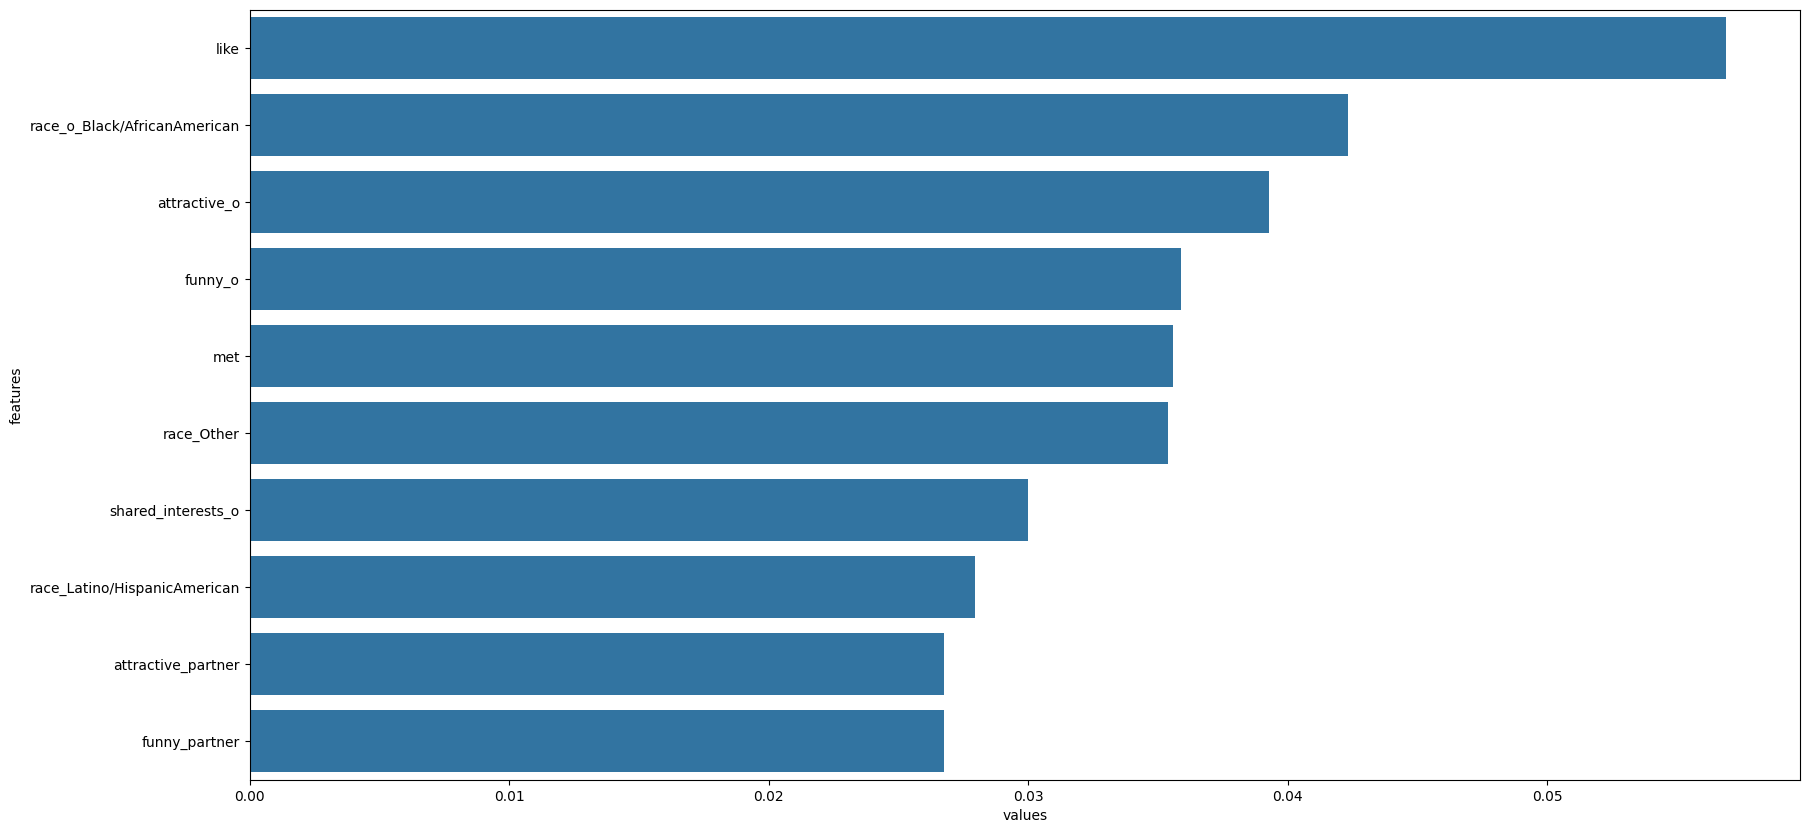

In [53]:
plt.figure(figsize=(20, 10)) # 그래프 크기 설정
sns.barplot(x='values', y='features', # ❶ x축: values(중요도), y축: features컬럼 설정
data=feature_imp.sort_values(by='values', ascending=False).head(10)) # ❷ values기준으로 내림차순 정렬